<a href="https://colab.research.google.com/github/maramadel6789-web/ml-models-models/blob/main/clustering/seeds_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
data=pd.read_csv('seeds.csv')
features = data[data.columns[ 0:6 ]]
print(data.shape)
print(features.shape)
print(features.head())



(210, 8)
(210, 6)
    area  perimeter  compactness  kernel_length  kernel_width  \
0  15.26      14.84       0.8710          5.763         3.312   
1  14.88      14.57       0.8811          5.554         3.333   
2  14.29      14.09       0.9050          5.291         3.337   
3  13.84      13.94       0.8955          5.324         3.379   
4  16.14      14.99       0.9034          5.658         3.562   

   asymmetry_coefficient  
0                  2.221  
1                  1.018  
2                  2.699  
3                  2.259  
4                  1.355  


In [2]:
from sklearn.preprocessing import MinMaxScaler
scaled_features= MinMaxScaler().fit_transform(features.values)
print(scaled_features[0:3])
print(scaled_features.min())
print(scaled_features.max())

[[0.44098206 0.50206612 0.5707804  0.48648649 0.48610121 0.18930164]
 [0.40509915 0.44628099 0.66243194 0.36880631 0.50106914 0.03288302]
 [0.34938621 0.34710744 0.87931034 0.22072072 0.50392017 0.25145302]]
0.0
1.0000000000000002


In [3]:
from sklearn.decomposition import PCA
pca= PCA(n_components=2).fit(scaled_features)
features_2d=pca.transform(scaled_features)
print(features_2d[0:3])
pca.explained_variance_ratio_




[[ 0.11883593 -0.09382469]
 [ 0.0696878  -0.31077233]
 [-0.03499184 -0.37044705]]


array([0.79778291, 0.12006331])

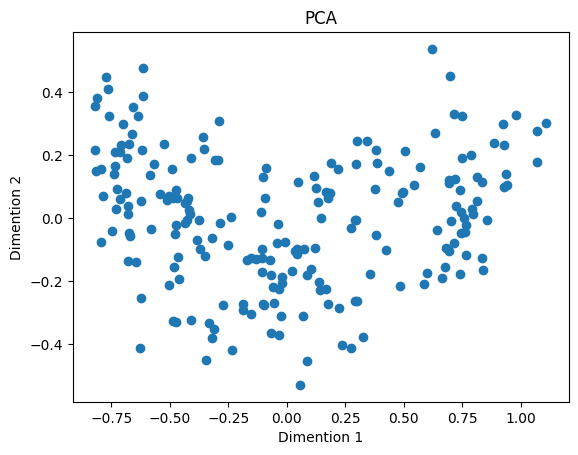

In [4]:
import matplotlib.pyplot as plt
plt.scatter(features_2d[:,0], features_2d[:,1])
plt.xlabel('Dimention 1')
plt.ylabel('Dimention 2')
plt.title('PCA')
plt.show()

[76.74711968954946, 31.111067614659582, 19.091487854412225, 16.635274673389194, 15.447003158751565, 13.3627562717892, 11.60185114744039, 10.55342759227731, 9.776754932967135, 8.838316165950483]


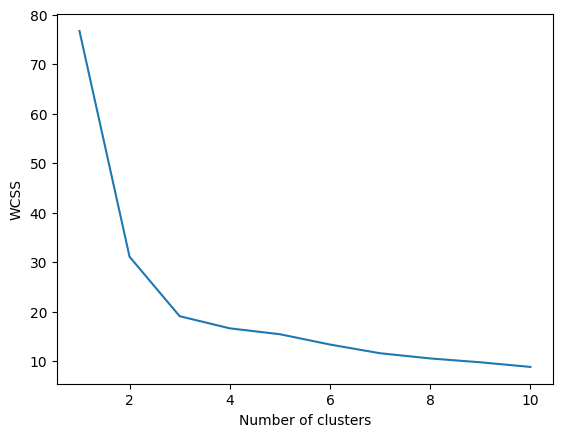

In [5]:
from sklearn.cluster import KMeans
wcss=[]
for i in range (1,11):
 Kmeans=  KMeans(n_clusters=i,random_state=0 )
 Kmeans.fit(scaled_features)
 wcss.append(Kmeans.inertia_)
print(wcss)
plt.plot(range(1,11),wcss)
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()




[2 2 2 2 2 2 2 2 0 2]


Text(0.5, 1.0, 'K-Means')

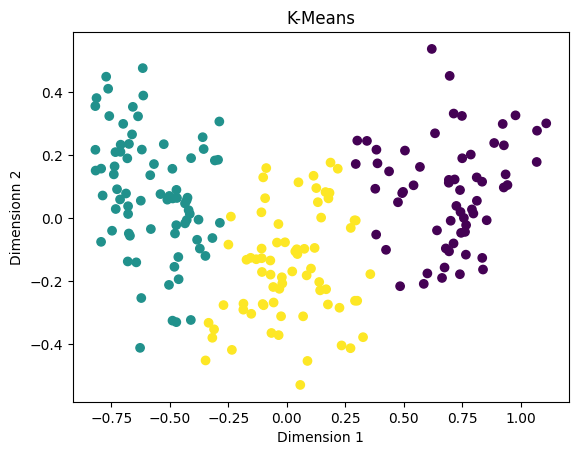

In [8]:
Kmeans=KMeans(n_clusters=3 , random_state=0).fit(scaled_features)
clusters= Kmeans.labels_
print(clusters[0:10])
plt.scatter(features_2d[:,0],features_2d[:,1], c= clusters)
plt.xlabel('Dimension 1')
plt.ylabel('Dimensionn 2')
plt.title('K-Means')


In [9]:
pd.crosstab(clusters,data['species'])

species,0,1,2
row_0,,,
0,2,60,0
1,10,0,67
2,58,10,3
